In [2]:
# Install the pretrained face-recognition runtime

!pip -q install insightface onnxruntime

In [4]:
# Load the LFW gallery–probe protocol

from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.datasets import fetch_lfw_people

random_seed = 42

lfw = fetch_lfw_people(
    min_faces_per_person=5,
    color=True,
    resize=1.0,
    download_if_missing=True
)

images = lfw.images
labels = lfw.target
identity_names = lfw.target_names

data_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/data"
)

results_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/results"
)

results_directory.mkdir(parents=True, exist_ok=True)

split_path = data_directory / "lfw_gallery_probe_split.csv"
gallery_probe_split = pd.read_csv(split_path)

gallery_metadata = gallery_probe_split[
    gallery_probe_split["split"] == "gallery"
].copy()

probe_metadata = gallery_probe_split[
    gallery_probe_split["split"] == "probe"
].copy()

gallery_indices = gallery_metadata["image_index"].to_numpy()
probe_indices = probe_metadata["image_index"].to_numpy()

gallery_images = images[gallery_indices]
probe_images = images[probe_indices]

print(f"Gallery images: {gallery_images.shape}")
print(f"Probe images: {probe_images.shape}")
print(f"Gallery identities: {gallery_metadata['identity_id'].nunique()}")
print(f"Probe identities: {probe_metadata['identity_id'].nunique()}")

Gallery images: (1269, 125, 94, 3)
Probe images: (846, 125, 94, 3)
Gallery identities: 423
Probe identities: 423


In [5]:
# Initialize the pretrained ArcFace-compatible recognition model

from insightface.app import FaceAnalysis

face_app = FaceAnalysis(
    name="buffalo_l",
    providers=["CPUExecutionProvider"]
)

face_app.prepare(
    ctx_id=-1,
    det_size=(320, 320)
)

print("Face-recognition model initialized successfully.")

download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:09<00:00, 30358.64KB/s]


Face-recognition model initialized successfully.


In [10]:
# Extract embeddings directly from the standardized LFW face crops

recognition_model = face_app.models["recognition"]

print(f"Recognition input size: {recognition_model.input_size}")
print(f"Recognition output shape: {recognition_model.output_shape}")


def prepare_for_recognition(image):
    image_uint8 = np.clip(
        image * 255,
        0,
        255
    ).astype(np.uint8)

    image_bgr = cv2.cvtColor(
        image_uint8,
        cv2.COLOR_RGB2BGR
    )

    image_bgr = cv2.resize(
        image_bgr,
        recognition_model.input_size,
        interpolation=cv2.INTER_CUBIC
    )

    return image_bgr


def extract_direct_embeddings(dataset_images, batch_size=64):
    prepared_images = [
        prepare_for_recognition(image)
        for image in dataset_images
    ]

    embedding_batches = []

    for start_index in tqdm(
        range(0, len(prepared_images), batch_size),
        desc="Extracting direct embeddings"
    ):
        batch_images = prepared_images[
            start_index:start_index + batch_size
        ]

        batch_embeddings = recognition_model.get_feat(
            batch_images
        )

        embedding_batches.append(batch_embeddings)

    embeddings = np.vstack(embedding_batches)

    embedding_norms = np.linalg.norm(
        embeddings,
        axis=1,
        keepdims=True
    )

    embeddings = embeddings / np.maximum(
        embedding_norms,
        1e-12
    )

    return embeddings


gallery_embeddings = extract_direct_embeddings(
    gallery_images
)

probe_embeddings = extract_direct_embeddings(
    probe_images
)

gallery_failed_indices = []
probe_failed_indices = []

print(f"Gallery embedding matrix: {gallery_embeddings.shape}")
print(f"Probe embedding matrix: {probe_embeddings.shape}")
print(f"Gallery embedding dimension: {gallery_embeddings.shape[1]}")
print(f"Probe embedding dimension: {probe_embeddings.shape[1]}")
print("Failed gallery detections: 0")
print("Failed probe detections: 0")

Recognition input size: (112, 112)
Recognition output shape: [1, 512]


Extracting direct embeddings:   0%|          | 0/20 [00:00<?, ?it/s]

Extracting direct embeddings:   0%|          | 0/14 [00:00<?, ?it/s]

Gallery embedding matrix: (1269, 512)
Probe embedding matrix: (846, 512)
Gallery embedding dimension: 512
Probe embedding dimension: 512
Failed gallery detections: 0
Failed probe detections: 0


In [11]:
# Verify embedding quality and remove unusable samples if necessary

gallery_valid = np.isfinite(gallery_embeddings).all(axis=1)
probe_valid = np.isfinite(probe_embeddings).all(axis=1)

print(f"Valid gallery embeddings: {gallery_valid.sum()} / {len(gallery_valid)}")
print(f"Valid probe embeddings: {probe_valid.sum()} / {len(probe_valid)}")

if not gallery_valid.all() or not probe_valid.all():
    raise ValueError(
        "Some faces were not detected. Inspect the failed indices "
        "before continuing."
    )

gallery_identity_ids = gallery_metadata["identity_id"].to_numpy()
probe_identity_ids = probe_metadata["identity_id"].to_numpy()

Valid gallery embeddings: 1269 / 1269
Valid probe embeddings: 846 / 846


In [12]:
# Construct one normalized ArcFace template per identity

def normalize_vectors(vectors):
    norms = np.linalg.norm(
        vectors,
        axis=1,
        keepdims=True
    )

    return vectors / np.maximum(norms, 1e-12)


identity_ids = np.sort(
    gallery_metadata["identity_id"].unique()
)

gallery_templates = []
template_identity_ids = []

for identity_id in identity_ids:
    identity_embeddings = gallery_embeddings[
        gallery_identity_ids == identity_id
    ]

    identity_template = identity_embeddings.mean(
        axis=0,
        keepdims=True
    )

    identity_template = normalize_vectors(
        identity_template
    )[0]

    gallery_templates.append(identity_template)
    template_identity_ids.append(identity_id)

gallery_templates = np.vstack(gallery_templates)
template_identity_ids = np.array(template_identity_ids)

print(f"Gallery template matrix: {gallery_templates.shape}")
print(f"Template identities: {len(template_identity_ids)}")

Gallery template matrix: (423, 512)
Template identities: 423


In [13]:
# Compute ArcFace probe-to-gallery similarities

similarity_matrix = probe_embeddings @ gallery_templates.T

ranked_template_positions = np.argsort(
    similarity_matrix,
    axis=1
)[:, ::-1]

ranked_identity_ids = template_identity_ids[
    ranked_template_positions
]

print(f"Similarity matrix shape: {similarity_matrix.shape}")
print(
    f"Similarity range: "
    f"{similarity_matrix.min():.4f}–"
    f"{similarity_matrix.max():.4f}"
)

Similarity matrix shape: (846, 423)
Similarity range: -0.2422–0.8420


In [14]:
# Evaluate clean ArcFace identification performance

top_1_predictions = ranked_identity_ids[:, 0]
top_5_predictions = ranked_identity_ids[:, :5]

rank_1_correct = (
    top_1_predictions == probe_identity_ids
)

rank_5_correct = np.any(
    top_5_predictions == probe_identity_ids[:, None],
    axis=1
)

rank_1_accuracy = rank_1_correct.mean()
rank_5_accuracy = rank_5_correct.mean()

print(f"Rank-1 accuracy: {rank_1_accuracy:.4f}")
print(f"Rank-5 accuracy: {rank_5_accuracy:.4f}")
print(f"Rank-1 correct: {rank_1_correct.sum()} / {len(rank_1_correct)}")
print(f"Rank-5 correct: {rank_5_correct.sum()} / {len(rank_5_correct)}")

Rank-1 accuracy: 0.9586
Rank-5 accuracy: 0.9787
Rank-1 correct: 811 / 846
Rank-5 correct: 828 / 846


In [15]:
# Analyze genuine and strongest-impostor similarities

true_positions = np.array([
    np.where(template_identity_ids == identity_id)[0][0]
    for identity_id in probe_identity_ids
])

true_similarity = similarity_matrix[
    np.arange(len(probe_identity_ids)),
    true_positions
]

strongest_impostor_similarity = []

for row_index, true_position in enumerate(true_positions):
    impostor_scores = np.delete(
        similarity_matrix[row_index],
        true_position
    )

    strongest_impostor_similarity.append(
        impostor_scores.max()
    )

strongest_impostor_similarity = np.array(
    strongest_impostor_similarity
)

similarity_margin = (
    true_similarity
    - strongest_impostor_similarity
)

arcface_results = pd.DataFrame({
    "probe_index": probe_indices,
    "true_identity_id": probe_identity_ids,
    "predicted_identity_id": top_1_predictions,
    "true_similarity": true_similarity,
    "strongest_impostor_similarity": strongest_impostor_similarity,
    "similarity_margin": similarity_margin,
    "rank_1_correct": rank_1_correct,
    "rank_5_correct": rank_5_correct
})

print(
    f"Mean genuine similarity: "
    f"{true_similarity.mean():.4f}"
)

print(
    f"Mean strongest-impostor similarity: "
    f"{strongest_impostor_similarity.mean():.4f}"
)

print(
    f"Mean similarity margin: "
    f"{similarity_margin.mean():.4f}"
)

print(
    f"Negative-margin cases: "
    f"{(similarity_margin < 0).sum()} / "
    f"{len(similarity_margin)}"
)

Mean genuine similarity: 0.5617
Mean strongest-impostor similarity: 0.2736
Mean similarity margin: 0.2881
Negative-margin cases: 35 / 846


In [16]:
# Compare the pixel and ArcFace baselines

pixel_summary_path = (
    results_directory / "clean_pixel_baseline_summary.csv"
)

if pixel_summary_path.exists():
    pixel_summary = pd.read_csv(pixel_summary_path)

    comparison = pd.DataFrame({
        "model": [
            "Pixel cosine baseline",
            "ArcFace-compatible model"
        ],
        "rank_1_accuracy": [
            pixel_summary.loc[
                pixel_summary["metric"] == "rank_1_accuracy",
                "value"
            ].iloc[0],
            rank_1_accuracy
        ],
        "rank_5_accuracy": [
            pixel_summary.loc[
                pixel_summary["metric"] == "rank_5_accuracy",
                "value"
            ].iloc[0],
            rank_5_accuracy
        ]
    })

    display(comparison)
else:
    print("Pixel baseline summary was not found.")

,model,rank_1_accuracy,rank_5_accuracy
0,Pixel cosine baseline,0.112293,0.197400
1,ArcFace-compatible model,0.958629,0.978723


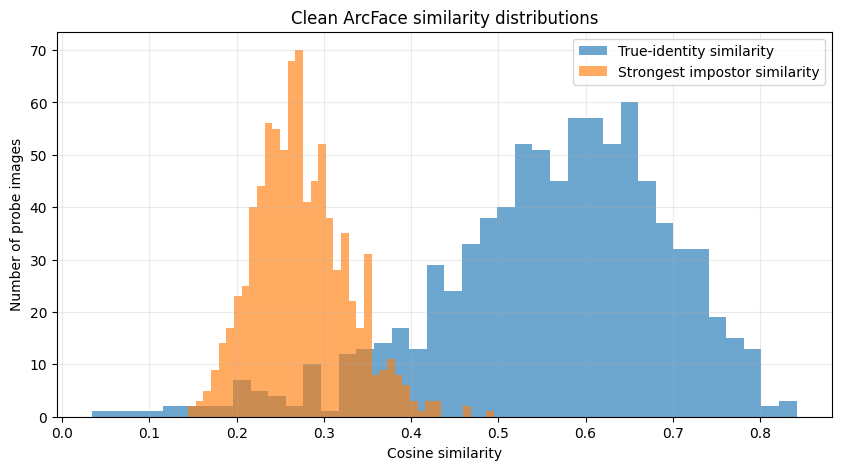

In [17]:
# Visualize clean ArcFace similarity distributions

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    arcface_results["true_similarity"],
    bins=40,
    alpha=0.65,
    label="True-identity similarity"
)

plt.hist(
    arcface_results["strongest_impostor_similarity"],
    bins=40,
    alpha=0.65,
    label="Strongest impostor similarity"
)

plt.xlabel("Cosine similarity")
plt.ylabel("Number of probe images")
plt.title("Clean ArcFace similarity distributions")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [18]:
# Save the clean ArcFace baseline results

arcface_results_path = (
    results_directory / "clean_arcface_baseline_results.csv"
)

arcface_summary = pd.DataFrame({
    "metric": [
        "rank_1_accuracy",
        "rank_5_accuracy",
        "mean_true_similarity",
        "mean_strongest_impostor_similarity",
        "mean_similarity_margin",
        "negative_margin_count"
    ],
    "value": [
        rank_1_accuracy,
        rank_5_accuracy,
        true_similarity.mean(),
        strongest_impostor_similarity.mean(),
        similarity_margin.mean(),
        (similarity_margin < 0).sum()
    ]
})

arcface_summary_path = (
    results_directory / "clean_arcface_baseline_summary.csv"
)

arcface_results.to_csv(
    arcface_results_path,
    index=False
)

arcface_summary.to_csv(
    arcface_summary_path,
    index=False
)

np.save(
    results_directory / "gallery_arcface_embeddings.npy",
    gallery_embeddings
)

np.save(
    results_directory / "probe_arcface_embeddings.npy",
    probe_embeddings
)

print(f"Saved detailed results to: {arcface_results_path}")
print(f"Saved summary results to: {arcface_summary_path}")

Saved detailed results to: /content/drive/MyDrive/Colab Notebooks/face_degradation/results/clean_arcface_baseline_results.csv
Saved summary results to: /content/drive/MyDrive/Colab Notebooks/face_degradation/results/clean_arcface_baseline_summary.csv
